In [1]:
%load_ext autoreload
%autoreload 2

In [47]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

from naive_bayes.datasets import load_ml25m, load_amazon_books, load_mind
from naive_bayes.datasets.utils import create_interaction_array

In [ ]:
def stride_array(arr, output_size):
    assert arr.shape[0] == arr.shape[1]

    # get output_size evenly spaced indices
    N = arr.shape[0]
    indices = np.linspace(0, N-1, output_size, dtype=int)  

    # index array
    return arr[np.ix_(indices, indices)]

In [ ]:
X_ml25m = create_interaction_array(load_ml25m()[0])
X_books = create_interaction_array(load_amazon_books())
X_mind = create_interaction_array(load_mind()[0])

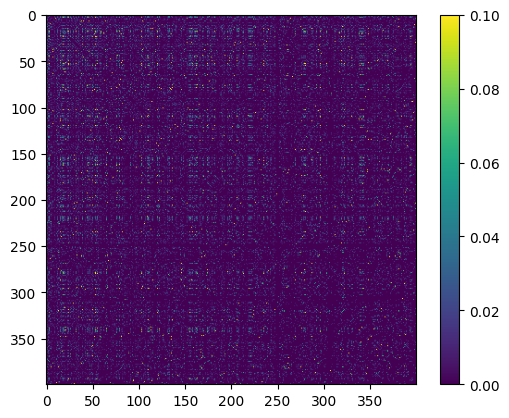

In [58]:
S = cosine_similarity(X_books.T)
np.fill_diagonal(S, 0)

plt.imshow(stride_array(S, 400), vmax=0.1)
plt.colorbar()

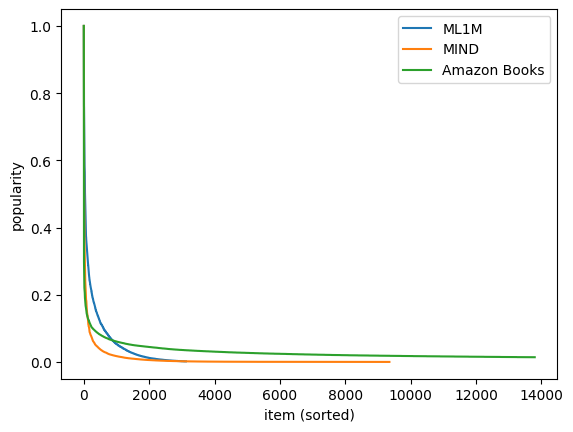

In [ ]:
plt.plot(X_ml25m.sum(axis=0) / X_ml25m.sum(axis=0).max(), label="ML25M")
plt.plot(X_mind.sum(axis=0) / X_mind.sum(axis=0).max(), label="MIND")
plt.plot(X_books.sum(axis=0) / X_books.sum(axis=0).max(), label="Amazon Books")
plt.xlabel("item (sorted)")
plt.ylabel("popularity")
plt.legend()